# Agentes que llaman herramientas: confiabilidad bajo fallas, sobrecarga y bucles

**Perfil:** IA y automatización  
**Datos:** simulación con reloj virtual (sin LLM ni red): servicio con capacidad finita, herramientas con efectos laterales y agentes guionados; semilla fija.

## Pregunta que guía el notebook

Un agente que usa herramientas hereda todos los problemas de los sistemas distribuidos: fallas transitorias, respuestas perdidas, servicios saturados y bucles que consumen presupuesto. Los reintentos parecen una solución simple, pero **pueden convertir una falla breve en una caída prolongada**. ¿Qué patrones (retroceso con *jitter*, presupuesto de reintentos, cortacircuitos, idempotencia, sagas, guardas) funcionan, cuánto, y con qué costos? Todo se verifica contra **fórmulas exactas** y por simulación con semilla.

## Recorrido

1. **Aritmética de reintentos:** éxito $1-p^n$ y amplificación de carga, verificados por simulación.
2. **Cuándo reintentar daña:** fallas permanentes y valor marginal de cada intento extra.
3. **Jitter y la manada atronadora:** cuatro estrategias frente a una falla sincronizada.
4. **Falla metaestable:** un servicio con colapso por congestión no se recupera por los reintentos; presupuesto de reintentos y cortacircuitos sí.
5. **Cortacircuitos:** máquina de estados, falsos disparos y tiempo de detección.
6. **Respuestas perdidas e idempotencia:** efectos duplicados, fórmula geométrica y garantía de una sola vez.
7. **Sagas:** todo-o-nada con compensaciones que también fallan.
8. **Control de agentes:** presupuesto, detector de bucles y su tasa de falsos positivos.
9. **Solicitudes cubiertas (*hedging*):** cola de latencia frente a carga extra.
10. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
import sys, itertools
from collections import Counter
sys.path.insert(0, "src")
from scipy import stats
from agentrt.policies import RetryPolicy, RetryBudget, CircuitBreaker, BudgetGuard, LoopDetector
from agentrt.sim import simulate_service, SimTool, Ledger, call_with_retries
from agentrt.saga import Step, run_saga, net_state
from agentrt.agent import run_agent

## 2. Aritmética de reintentos

Si cada intento falla con probabilidad $p$ de forma independiente y se permiten $n$ intentos:

- éxito: $1-p^{n}$;
- intentos esperados por solicitud: $\sum_{k=0}^{n-1}p^{k}=\dfrac{1-p^{n}}{1-p}$ (esa es también la **amplificación de carga**).

Se verifica con la simulación (servicio sin saturación, 20.000 solicitudes por celda).

In [2]:
filas = []
for p, n in itertools.product([0.05, 0.2, 0.4, 0.6], [1, 2, 3, 5]):
    r = simulate_service(np.full(200, 100), 10 ** 9, p, RetryPolicy(n, 0.2, 2.0, "full"), np.random.default_rng(int(1000 * p) + n))
    filas.append({"p": p, "n": n, "exito_sim": r["goodput"], "exito_teorico": 1 - p ** n, "ampl_sim": r["amplification"], "ampl_teorica": (1 - p ** n) / (1 - p)})
ar = pd.DataFrame(filas); ar["err_exito"] = ar.exito_sim - ar.exito_teorico; ar["err_ampl"] = ar.ampl_sim - ar.ampl_teorica; ar.round(4)

,p,n,exito_sim,exito_teorico,ampl_sim,ampl_teorica,err_exito,err_ampl
0,0.0500,1,0.9495,0.9500,1.0000,1.0000,-0.0005,0.0000
1,0.0500,2,0.9974,0.9975,1.0506,1.0500,-0.0001,0.0006
2,0.0500,3,0.9999,0.9999,1.0510,1.0525,0.0000,-0.0014
3,0.0500,5,1.0000,1.0000,1.0525,1.0526,0.0000,-0.0002
4,0.2000,1,0.8008,0.8000,1.0000,1.0000,0.0007,0.0000
5,0.2000,2,0.9578,0.9600,1.1997,1.2000,-0.0022,-0.0003
6,0.2000,3,0.9917,0.9920,1.2408,1.2400,-0.0003,0.0008
7,0.2000,5,0.9994,0.9997,1.2532,1.2496,-0.0003,0.0036
8,0.4000,1,0.5950,0.6000,1.0000,1.0000,-0.0050,0.0000
9,0.4000,2,0.8432,0.8400,1.3961,1.4000,0.0032,-0.0039


In [3]:
print("Lectura:")
print(f"  El maximo error absoluto de la simulacion es {ar.err_exito.abs().max():.4f} en el exito y {ar.err_ampl.abs().max():.4f} en la amplificacion: la simulacion reproduce la teoria.")
x = ar[(ar.p == 0.4)].set_index("n")
print(f"  Con p=0.4: 1 intento da {x.loc[1, 'exito_teorico']:.0%}, 3 dan {x.loc[3, 'exito_teorico']:.1%}, 5 dan {x.loc[5, 'exito_teorico']:.1%}; la carga sube a {x.loc[3, 'ampl_teorica']:.2f}x y {x.loc[5, 'ampl_teorica']:.2f}x. El retorno es decreciente y la amplificacion tiene un limite 1/(1-p) = {1 / (1 - 0.4):.2f}x.")

Lectura:
  El maximo error absoluto de la simulacion es 0.0050 en el exito y 0.0091 en la amplificacion: la simulacion reproduce la teoria.
  Con p=0.4: 1 intento da 60%, 3 dan 93.6%, 5 dan 99.0%; la carga sube a 1.56x y 1.65x. El retorno es decreciente y la amplificacion tiene un limite 1/(1-p) = 1.67x.


## 3. Cuándo reintentar daña

El análisis anterior supone fallas **transitorias**. Si una fracción $f$ de las solicitudes falla **siempre** (entrada inválida, permiso denegado), reintentarlas solo gasta carga:
$$\text{éxito}=(1-f)(1-p^{n}),\qquad \text{carga}=f\,n+(1-f)\frac{1-p^{n}}{1-p}.$$
El **valor marginal** del intento $n$ es el éxito adicional por unidad de carga adicional (con $f=0$ vale siempre $1-p$). Se calcula para $p=0{,}3$ y distintas fracciones $f$.

In [4]:
p = 0.3
exito = lambda f, n: (1 - f) * (1 - p ** n); carga = lambda f, n: f * n + (1 - f) * (1 - p ** n) / (1 - p)
marg = lambda f, n: (exito(f, n) - exito(f, n - 1)) / (carga(f, n) - carga(f, n - 1))          # exito adicional por unidad de carga adicional del intento n
mv = pd.DataFrame([{"f_permanentes": f, "n": n, "exito": exito(f, n), "carga": carga(f, n), "marginal": marg(f, n) if n > 1 else np.nan} for f in (0.0, 0.1, 0.3, 0.5) for n in range(1, 7)])
rg = np.random.default_rng(0); N = 200_000; perm = rg.random(N) < 0.3; ok_mc = np.zeros(N, bool); att = np.zeros(N)
for k in range(3):                                                   # Monte Carlo del mismo modelo (f=0.3, n=3)
    a_ = ~ok_mc; att[a_] += 1; ok_mc[a_ & ~perm & (rg.random(N) >= p)] = True
print(f"Monte Carlo (f=0.3, n=3): exito {ok_mc.mean():.4f} (teorico {exito(0.3, 3):.4f}); carga {att.mean():.4f} (teorica {carga(0.3, 3):.4f})")
mv.pivot(index="n", columns="f_permanentes", values="marginal").round(3)

Monte Carlo (f=0.3, n=3): exito 0.6813 (teorico 0.6811); carga 1.8736 (teorica 1.8730)


f_permanentes,0.0000,0.1000,0.3000,0.5000
n,,,,
1,NaN,NaN,NaN,NaN
2,0.7000,0.5110,0.2880,0.1620
3,0.7000,0.3130,0.1210,0.0580
4,0.7000,0.1370,0.0410,0.0180
5,0.7000,0.0480,0.0130,0.0060
6,0.7000,0.0150,0.0040,0.0020


In [5]:
tabla = mv.pivot(index="n", columns="f_permanentes", values="carga")
print("Lectura:")
print(f"  Con {0.5:.0%} de fallas permanentes, 5 intentos cuestan {tabla.loc[5, 0.5]:.2f}x de carga para un exito de {mv[(mv.f_permanentes == 0.5) & (mv.n == 5)].exito.iloc[0]:.1%}, frente a {tabla.loc[1, 0.5]:.2f}x y {mv[(mv.f_permanentes == 0.5) & (mv.n == 1)].exito.iloc[0]:.1%} con un intento: la mayor parte de la carga adicional se desperdicia.")
print("  Regla practica: reintentar solo errores clasificados como transitorios (timeouts, 429, 503) y nunca los de validacion o autorizacion.")

Lectura:
  Con 50% de fallas permanentes, 5 intentos cuestan 3.21x de carga para un exito de 49.9%, frente a 1.00x y 35.0% con un intento: la mayor parte de la carga adicional se desperdicia.
  Regla practica: reintentar solo errores clasificados como transitorios (timeouts, 429, 503) y nunca los de validacion o autorizacion.


## 4. Jitter y la manada atronadora

Mil clientes fallan **a la vez** (por ejemplo, el servicio reinicia en $t=0$). Si todos reintentan con el mismo retroceso, vuelven a chocar a la vez. Se simulan tres rondas de reintento con cada estrategia de *jitter* y se mide el **pico de carga** (solicitudes por ventana de 100 ms) acumulado en cuatro rondas de reintento. El retroceso base es 1 s con tope de 30 s.

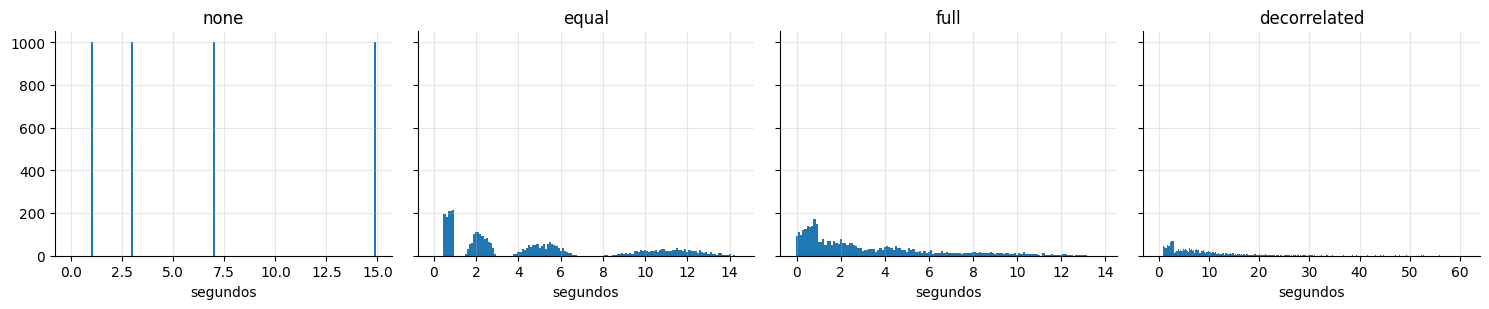

,pico_por_100ms,pico/clientes,ventanas_con_carga,desvio_tiempos_ronda1
jitter,,,,
none,1000,1.0000,4,0.0000
equal,212,0.2120,117,0.1420
full,173,0.1730,136,0.2850
decorrelated,70,0.0700,409,0.5690


In [6]:
def rondas(jitter, n_clientes=1000, rondas_=4, seed=0):
    rg = np.random.default_rng(seed); pol = RetryPolicy(10, 1.0, 30.0, jitter); t = np.zeros(n_clientes); prev = [None] * n_clientes; llegadas = [t.copy()]
    for k in range(1, rondas_ + 1):
        d = np.array([pol.delay(k, rg, prev[i]) for i in range(n_clientes)]); prev = list(d); t = t + d; llegadas.append(t.copy())
    return llegadas
filas = []; fig, ax = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for a_, jit in zip(ax, ("none", "equal", "full", "decorrelated")):
    ll = rondas(jit); todos = np.concatenate(ll[1:]); h, _ = np.histogram(todos, bins=np.arange(0, todos.max() + 0.1, 0.1)); a_.bar(np.arange(len(h)) * 0.1, h, width=0.1); a_.set_title(jit); a_.set_xlabel("segundos")
    filas.append({"jitter": jit, "pico_por_100ms": h.max(), "pico/clientes": h.max() / 1000, "ventanas_con_carga": int((h > 0).sum()), "desvio_tiempos_ronda1": float(np.std(ll[1] - ll[0]))})
plt.tight_layout(); plt.show(); jt = pd.DataFrame(filas).set_index("jitter"); jt.round(3)

In [7]:
print("Lectura:")
print(f"  Sin jitter los 1.000 clientes reintentan juntos en cada ronda: pico de {int(jt.loc['none', 'pico_por_100ms'])} solicitudes por ventana de 100 ms ({jt.loc['none', 'pico/clientes']:.0%} de la poblacion). Con jitter completo el pico baja a {int(jt.loc['full', 'pico_por_100ms'])} ({jt.loc['full', 'pico/clientes']:.1%}), {jt.loc['none', 'pico_por_100ms'] / jt.loc['full', 'pico_por_100ms']:.0f} veces menos; con decorrelado, {int(jt.loc['decorrelated', 'pico_por_100ms'])}.")
print(f"  Ranking de picos (menor es mejor): " + " < ".join(jt.sort_values('pico_por_100ms').index) + ". El jitter 'equal' conserva una cota inferior de espera (techo/2) pero reparte menos que 'full'.")

Lectura:
  Sin jitter los 1.000 clientes reintentan juntos en cada ronda: pico de 1000 solicitudes por ventana de 100 ms (100% de la poblacion). Con jitter completo el pico baja a 173 (17.3%), 6 veces menos; con decorrelado, 70.
  Ranking de picos (menor es mejor): decorrelated < full < equal < none. El jitter 'equal' conserva una cota inferior de espera (techo/2) pero reparte menos que 'full'.


## 5. Falla metaestable: cuando los reintentos mantienen la caída

Un servicio recibe 100 solicitudes/s con capacidad de 150/s. Una caída de capacidad a 30/s durante 20 s (t = 60–80) es el **disparador**. Con **colapso por congestión** ($\alpha=2$: las solicitudes bien atendidas son $L\,(C/L)^{2}$, que *decrece* con la carga $L$ al saturar), la carga extra de los reintentos puede mantener el servicio colapsado aunque el disparador ya haya terminado: es una falla **metaestable**. Se comparan seis configuraciones de cliente.

                                 goodput_total  amplificacion  pico_carga_ofrecida  ok_ultimos_50s  recuperacion_s  rechazos_breaker
configuracion                                                                                                                       
sin reintentos (n=1)                    0.9390         1.0000             100.0000          1.0000          0.0000                 0
n=3 sin jitter                          0.9390         1.1500             300.0000          1.0000          3.0000                 0
n=5 jitter completo                     0.6950         3.0310             512.0000          0.6370             NaN                 0
n=5 + presupuesto de reintentos         0.9390         1.0060             116.0000          1.0000          0.0000                 0
n=5 + cortacircuitos                    0.9220         0.9340             100.0000          1.0000          4.0000              2355
n=5 + ambos                             0.9220         0.9340        

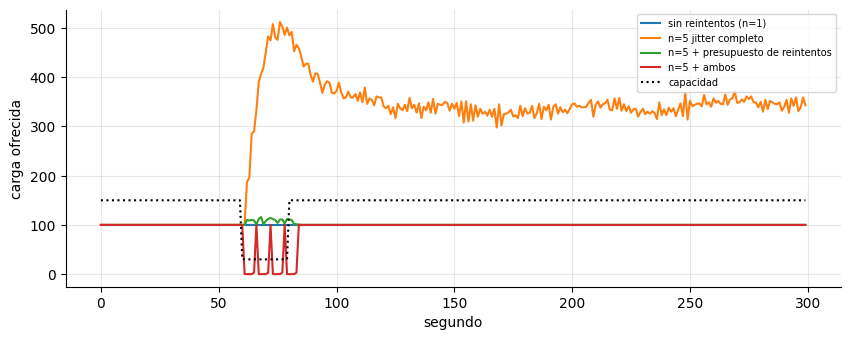

In [8]:
T = 300; arr = np.full(T, 100); cap = np.r_[np.full(60, 150), np.full(20, 30), np.full(T - 80, 150)]; COLAPSO = 2.0
def correr_ms(pol, budget=False, breaker=False, seed=1, alpha=COLAPSO):
    return simulate_service(arr, cap, 0.0, pol, np.random.default_rng(seed), budget=RetryBudget(0.1, 10.0) if budget else None, breaker=CircuitBreaker(0.5, 20, 10, 5.0, 3) if breaker else None, collapse=alpha)
CONF = {"sin reintentos (n=1)": (RetryPolicy(1), False, False), "n=3 sin jitter": (RetryPolicy(3, 0.5, 4.0, "none"), False, False), "n=5 jitter completo": (RetryPolicy(5, 0.5, 8.0, "full"), False, False),
        "n=5 + presupuesto de reintentos": (RetryPolicy(5, 0.5, 8.0, "full"), True, False), "n=5 + cortacircuitos": (RetryPolicy(5, 0.5, 8.0, "full"), False, True), "n=5 + ambos": (RetryPolicy(5, 0.5, 8.0, "full"), True, True)}
def tiempo_recuperacion(ok, fin_disparo=80, umbral=0.95, ventana=10):
    for t in range(fin_disparo, len(ok) - ventana):
        if (ok[t:t + ventana] >= umbral * 100).all(): return t - fin_disparo
    return np.nan
filas = []; series = {}
for nombre, (pol, bud, brk) in CONF.items():
    r = correr_ms(pol, bud, brk); series[nombre] = r["offered"]
    filas.append({"configuracion": nombre, "goodput_total": r["goodput"], "amplificacion": r["amplification"], "pico_carga_ofrecida": r["offered"].max(), "ok_ultimos_50s": r["ok"][250:300].mean() / 100, "recuperacion_s": tiempo_recuperacion(r["ok"]), "rechazos_breaker": r["rejected_by_breaker"]})
ms = pd.DataFrame(filas).set_index("configuracion"); print(ms.round(3).to_string())
fig, ax = plt.subplots(figsize=(10, 3.6))
for nombre in ("sin reintentos (n=1)", "n=5 jitter completo", "n=5 + presupuesto de reintentos", "n=5 + ambos"): ax.plot(series[nombre][:300], label=nombre)
ax.plot(cap, "k:", label="capacidad"); ax.set_xlabel("segundo"); ax.set_ylabel("carga ofrecida"); ax.legend(fontsize=7); plt.show()

In [9]:
print("Lectura:")
print(f"  Con reintentos agresivos (n=5, jitter completo) el servicio NO se recupera: en los ultimos 50 s solo atiende {ms.loc['n=5 jitter completo', 'ok_ultimos_50s']:.0%} de la demanda (carga pico {ms.loc['n=5 jitter completo', 'pico_carga_ofrecida']:.0f}/s, amplificacion {ms.loc['n=5 jitter completo', 'amplificacion']:.1f}x), mientras que sin reintentos se recupera en {ms.loc['sin reintentos (n=1)', 'recuperacion_s']:.0f} s y n=3 sin jitter en {ms.loc['n=3 sin jitter', 'recuperacion_s']:.0f} s.")
print(f"  El presupuesto de reintentos (10% de las llamadas) limita la amplificacion a {ms.loc['n=5 + presupuesto de reintentos', 'amplificacion']:.2f}x y devuelve el sistema a {ms.loc['n=5 + presupuesto de reintentos', 'ok_ultimos_50s']:.0%} de exito; el cortacircuitos ({ms.loc['n=5 + cortacircuitos', 'rechazos_breaker']:.0f} rechazos) lo logra a costa de rechazar solicitudes durante el disparador.")
print(f"  Goodput total: " + ", ".join(f"{n}: {v:.1%}" for n, v in ms.goodput_total.items()) + ". Reintentar mas NO da mas exito global cuando el reintento causa el colapso.")

Lectura:
  Con reintentos agresivos (n=5, jitter completo) el servicio NO se recupera: en los ultimos 50 s solo atiende 64% de la demanda (carga pico 512/s, amplificacion 3.0x), mientras que sin reintentos se recupera en 0 s y n=3 sin jitter en 3 s.
  El presupuesto de reintentos (10% de las llamadas) limita la amplificacion a 1.01x y devuelve el sistema a 100% de exito; el cortacircuitos (2355 rechazos) lo logra a costa de rechazar solicitudes durante el disparador.
  Goodput total: sin reintentos (n=1): 93.9%, n=3 sin jitter: 93.9%, n=5 jitter completo: 69.5%, n=5 + presupuesto de reintentos: 93.9%, n=5 + cortacircuitos: 92.2%, n=5 + ambos: 92.2%. Reintentar mas NO da mas exito global cuando el reintento causa el colapso.


## 6. Cortacircuitos: máquina de estados, falsos disparos y detección

**Máquina de estados** (se verifica con una secuencia guionada): cerrado → abierto al superar el umbral de fallos en la ventana → semiabierto tras el enfriamiento → cerrado si las sondas tienen éxito.

**Compromiso**: un umbral bajo detecta antes pero dispara en falso con un servicio sano. Con un servicio sano que falla con probabilidad $p_0=10\,\%$, se estima por Monte Carlo la probabilidad de que el cortacircuitos abra al menos una vez en 1.000 llamadas, según ventana y umbral; y, con el servicio caído (100 % de fallos), cuántas llamadas hacen falta para abrir.

In [10]:
cb = CircuitBreaker(threshold=0.5, window=10, min_calls=4, cooldown=5.0, probes=2); t = 0.0; log = []
for ok in [True, True, False, False, False, False]: cb.allow(t); cb.record(ok, t); log.append((t, cb.state)); t += 1
log.append((t, "rechaza" if not cb.allow(t) else "pasa")); t += 5; log.append((t, "sonda" if cb.allow(t) else "rechaza")); cb.record(True, t); t += 0.1; cb.allow(t); cb.record(True, t); log.append((t, cb.state))
print("Secuencia guionada (tiempo, estado):", log); print("Transiciones:", cb.transitions)
def abre(p_fallo, thr, window, min_calls, seed, horizonte=1000):
    c = CircuitBreaker(thr, window, min_calls, 5.0, 3); rg = np.random.default_rng(seed)
    for i in range(horizonte):
        c.allow(float(i)); c.record(bool(rg.random() >= p_fallo), float(i))
        if c.state == "open": return i + 1
    return None
filas = []
for thr, mc in itertools.product([0.2, 0.3, 0.5], [5, 10, 20]):
    sano = [abre(0.10, thr, 20, mc, s) for s in range(400)]; degr = [abre(0.60, thr, 20, mc, 10_000 + s) for s in range(400)]; caido = abre(1.0, thr, 20, mc, 0)
    filas.append({"umbral": thr, "min_llamadas": mc, "P(falso_disparo_en_1000)": np.mean([x is not None for x in sano]), "llamadas_para_abrir_servicio_caido": caido, "llamadas_para_abrir_con_60%_fallos": np.mean([x for x in degr if x is not None]) if any(x is not None for x in degr) else np.nan})
cbt = pd.DataFrame(filas); print("Probabilidad de falso disparo con servicio sano (10% de fallos), ventana 20:"); print(cbt.pivot(index="min_llamadas", columns="umbral", values="P(falso_disparo_en_1000)").round(3).to_string())
print("\nLlamadas hasta abrir con servicio caido:"); print(cbt.pivot(index="min_llamadas", columns="umbral", values="llamadas_para_abrir_servicio_caido").to_string())
print("\nLlamadas hasta abrir con 60% de fallos (servicio degradado):"); print(cbt.pivot(index="min_llamadas", columns="umbral", values="llamadas_para_abrir_con_60%_fallos").round(1).to_string())

Secuencia guionada (tiempo, estado): [(0.0, 'closed'), (1.0, 'closed'), (2.0, 'closed'), (3.0, 'open'), (4.0, 'open'), (5.0, 'open'), (6.0, 'rechaza'), (11.0, 'sonda'), (11.1, 'closed')]
Transiciones: [(3.0, 'open'), (11.0, 'half_open'), (11.1, 'closed')]


Probabilidad de falso disparo con servicio sano (10% de fallos), ventana 20:
umbral        0.2000  0.3000  0.5000
min_llamadas                        
5             1.0000  0.8400  0.0120
10            1.0000  0.8280  0.0050
20            1.0000  0.8180  0.0020

Llamadas hasta abrir con servicio caido:
umbral        0.2000  0.3000  0.5000
min_llamadas                        
5                  5       5       5
10                10      10      10
20                20      20      20

Llamadas hasta abrir con 60% de fallos (servicio degradado):
umbral        0.2000  0.3000  0.5000
min_llamadas                        
5             5.1000  5.2000  6.6000
10           10.0000 10.1000 11.4000
20           20.0000 20.0000 20.8000


In [11]:
print("Lectura:")
print(f"  La secuencia guionada recorre closed -> open -> half_open -> closed ({[s for _, s in cb.transitions]}).")
f_ = cbt.set_index(["umbral", "min_llamadas"])
print(f"  Servicio sano (10% de fallos): con umbral 20% hay {f_.loc[(0.2, 5), 'P(falso_disparo_en_1000)']:.0%} de falsos disparos en 1.000 llamadas, con 30% {f_.loc[(0.3, 5), 'P(falso_disparo_en_1000)']:.0%} y con 50% {f_.loc[(0.5, 5), 'P(falso_disparo_en_1000)']:.0%}: el umbral debe quedar muy por encima de la tasa de fallos normal.")
print(f"  Servicio caido: abre exactamente tras `min_llamadas` fallos (5, 10 o 20). Servicio degradado (60% de fallos) y umbral 50%: abre tras {f_.loc[(0.5, 5), 'llamadas_para_abrir_con_60%_fallos']:.1f} llamadas con min=5 y {f_.loc[(0.5, 20), 'llamadas_para_abrir_con_60%_fallos']:.1f} con min=20: exigir mas llamadas minimas retrasa la reaccion pero reduce el ruido.")

Lectura:
  La secuencia guionada recorre closed -> open -> half_open -> closed (['open', 'half_open', 'closed']).
  Servicio sano (10% de fallos): con umbral 20% hay 100% de falsos disparos en 1.000 llamadas, con 30% 84% y con 50% 1%: el umbral debe quedar muy por encima de la tasa de fallos normal.
  Servicio caido: abre exactamente tras `min_llamadas` fallos (5, 10 o 20). Servicio degradado (60% de fallos) y umbral 50%: abre tras 6.6 llamadas con min=5 y 20.8 con min=20: exigir mas llamadas minimas retrasa la reaccion pero reduce el ruido.


## 7. Respuestas perdidas e idempotencia

El caso peligroso: el servicio **aplica** el efecto (cobro, envío de correo, escritura) pero la **respuesta se pierde**. El cliente ve un *timeout*, reintenta y, sin protección, el efecto se aplica de nuevo. Con probabilidad $\ell$ de perder la respuesta y hasta $n$ intentos, las aplicaciones esperadas por operación son $\sum_{k=0}^{n-1}\ell^{k}$ y los **duplicados** esperados, $\sum_{k=1}^{n-1}\ell^{k}$. Con **clave de idempotencia** (la misma clave en todos los intentos) el servidor reconoce la repetición y aplica el efecto **una sola vez**.

In [12]:
filas = []
for l in (0.05, 0.1, 0.2, 0.4):
    for modo in ("sin clave", "clave distinta por intento", "misma clave"):
        led = Ledger(); tool = SimTool(led, 0.0, l, idempotent=(modo != "sin clave")); rg = np.random.default_rng(int(l * 100)); pol = RetryPolicy(6, 0.01, 0.1); N = 4000
        res = [call_with_retries(tool, i, pol, rg, use_key=(modo == "misma clave")) for i in range(N)]
        filas.append({"p_respuesta_perdida": l, "modo": modo, "duplicados_por_operacion": led.duplicates() / N, "duplicados_teoricos": sum(l ** k for k in range(1, 6)) if modo != "misma clave" else 0.0, "operaciones_con_efecto_repetido": sum(v > 1 for v in led.applied.values()) / N})
ide = pd.DataFrame(filas); ide.pivot(index="p_respuesta_perdida", columns="modo", values="duplicados_por_operacion").round(4)

modo,clave distinta por intento,misma clave,sin clave
p_respuesta_perdida,,,
0.0500,0.0538,0.0000,0.0538
0.1000,0.1050,0.0000,0.1050
0.2000,0.2458,0.0000,0.2458
0.4000,0.6515,0.0000,0.6515


In [13]:
sc = ide[ide.modo == "sin clave"].set_index("p_respuesta_perdida"); mk = ide[ide.modo == "misma clave"].set_index("p_respuesta_perdida"); dk = ide[ide.modo == "clave distinta por intento"].set_index("p_respuesta_perdida")
print("Lectura:")
print(f"  Sin clave, los duplicados por operacion coinciden con la serie geometrica (error maximo {np.abs(sc.duplicados_por_operacion - sc.duplicados_teoricos).max():.4f}): con 40% de respuestas perdidas hay {sc.loc[0.4, 'duplicados_por_operacion']:.2f} efectos de mas por operacion, y {sc.loc[0.4, 'operaciones_con_efecto_repetido']:.0%} de las operaciones se aplican mas de una vez.")
print(f"  Con la MISMA clave en todos los intentos los duplicados son {mk.duplicados_por_operacion.max():.0f} para cualquier tasa de perdida. Si la clave cambia en cada intento no hay proteccion (duplicados {dk.loc[0.4, 'duplicados_por_operacion']:.2f}): la clave debe generarse una vez por operacion logica, no por intento.")

Lectura:
  Sin clave, los duplicados por operacion coinciden con la serie geometrica (error maximo 0.0083): con 40% de respuestas perdidas hay 0.65 efectos de mas por operacion, y 39% de las operaciones se aplican mas de una vez.
  Con la MISMA clave en todos los intentos los duplicados son 0 para cualquier tasa de perdida. Si la clave cambia en cada intento no hay proteccion (duplicados 0.65): la clave debe generarse una vez por operacion logica, no por intento.


## 8. Sagas: todo o nada con compensaciones que también fallan

Una reserva de viaje tiene tres pasos (vuelo, hotel, auto), cada uno con probabilidad $f_i$ de fallar. Si uno falla se **compensan** en orden inverso los ya aplicados. Probabilidad de confirmar todo: $\prod(1-f_i)$. Pero las compensaciones también pueden fallar: con $r$ reintentos y probabilidad $c$ de fallo por intento, una compensación se agota con probabilidad $c^{r}$ y deja la saga **atascada** (estado intermedio que requiere intervención). Se verifica el invariante de estado neto (cada paso en {0,1}; confirmada ⇒ todos 1; compensada ⇒ todos 0) y la probabilidad de atasco.

In [14]:
steps = [Step("vuelo", 0.10, 0.3), Step("hotel", 0.15, 0.3), Step("auto", 0.20, 0.3)]; R = 20_000; rg = np.random.default_rng(0); filas = []
for r_ in (1, 2, 3, 5):
    est = Counter(); viol = 0
    for _ in range(R):
        led = Ledger(); out = run_saga(steps, led, rg, comp_retries=r_); ns = net_state(led, 3); est[out["status"]] += 1
        viol += not (all(x in (0, 1) for x in ns) and (out["status"] != "committed" or ns == [1, 1, 1]) and (out["status"] != "compensated" or ns == [0, 0, 0]))
    # teoria: aplicados antes del fallo i; cada compensacion se agota con prob c^r
    c = 0.3 ** r_; f = [s.p_fail for s in steps]; p_fallo_en = [np.prod([1 - x for x in f[:i]]) * f[i] for i in range(3)]; p_atasco = sum(p_fallo_en[i] * (1 - (1 - c) ** i) for i in range(3))
    filas.append({"reintentos_compensacion": r_, "confirmada": est["committed"] / R, "compensada": est["compensated"] / R, "atascada": est["stuck"] / R, "atascada_teorica": p_atasco, "violaciones_invariante": viol})
sga = pd.DataFrame(filas).set_index("reintentos_compensacion"); print(f"P(confirmar) teorica = {np.prod([1 - s.p_fail for s in steps]):.4f}"); sga.round(4)

P(confirmar) teorica = 0.6120


,confirmada,compensada,atascada,atascada_teorica,violaciones_invariante
reintentos_compensacion,,,,,
1,0.6128,0.2720,0.1151,0.1185,0
2,0.6088,0.3505,0.0406,0.0385,0
3,0.6113,0.3766,0.0121,0.0118,0
5,0.6122,0.3870,0.0008,0.0011,0


In [15]:
print("Lectura:")
print(f"  Confirmadas: {sga.confirmada.mean():.3f} (teorica {np.prod([1 - s.p_fail for s in steps]):.3f}); el invariante de estado neto no se viola ninguna vez ({int(sga.violaciones_invariante.sum())} violaciones en {4 * R:,} sagas).")
print(f"  Con 1 intento de compensacion queda atascado el {sga.loc[1, 'atascada']:.2%} de las sagas (teorico {sga.loc[1, 'atascada_teorica']:.2%}); con 5 intentos, {sga.loc[5, 'atascada']:.4%} (teorico {sga.loc[5, 'atascada_teorica']:.4%}). Cada reintento de compensacion multiplica el riesgo residual por c=0.3.")
print("  Las compensaciones deben ser idempotentes y reintentables hasta tener exito, con una cola de intervencion manual para lo que queda atascado.")

Lectura:
  Confirmadas: 0.611 (teorica 0.612); el invariante de estado neto no se viola ninguna vez (0 violaciones en 80,000 sagas).
  Con 1 intento de compensacion queda atascado el 11.51% de las sagas (teorico 11.85%); con 5 intentos, 0.0850% (teorico 0.1071%). Cada reintento de compensacion multiplica el riesgo residual por c=0.3.
  Las compensaciones deben ser idempotentes y reintentables hasta tener exito, con una cola de intervencion manual para lo que queda atascado.


## 9. Control del agente: presupuesto y detector de bucles

Un agente que reformula la misma búsqueda sin progreso puede consumir presupuesto indefinidamente. Dos guardas: **presupuesto** (pasos/costo) y **detector de bucles** (la misma llamada $k$ veces en una ventana). Un detector demasiado sensible marca como bucle los **reintentos legítimos** de una llamada transitoriamente fallida. Con probabilidad de fallo transitorio $q$, la probabilidad de que una operación legítima genere $k$ llamadas idénticas seguidas es $q^{k-1}$ (los $k-1$ primeros intentos fallan). Se compara con la simulación y se mide el costo de un bucle real con y sin guardas.

In [16]:
def legitimo(q, k, ventana, N, seed=0):
    rg = np.random.default_rng(seed); fp = 0
    for _ in range(N):
        det = LoopDetector(k, ventana); intentos = 1
        while rg.random() < q and intentos < 12: intentos += 1
        for i in range(intentos): fp += det.observe("api", {"x": 1})            # una operacion con `intentos` llamadas identicas
        # se cuenta falso positivo si la operacion fue marcada en algun momento
    return fp
filas = []
for q in (0.1, 0.3, 0.5):
    for k in (2, 3, 5):
        N = 6000; rg = np.random.default_rng(int(q * 100) + k); marcadas = 0
        for _ in range(N):
            det = LoopDetector(k, 12); intentos = 1
            while rg.random() < q and intentos < 12: intentos += 1
            marcadas += any(det.observe("api", {"x": 1}) for _ in range(intentos))
        filas.append({"p_falla_transitoria": q, "k_repeticiones": k, "falsos_positivos": marcadas / N, "teorico_q^(k-1)": q ** (k - 1)})
dfp = pd.DataFrame(filas); print(dfp.pivot(index="p_falla_transitoria", columns="k_repeticiones", values="falsos_positivos").round(4).to_string())
# costo de un bucle real (el agente reformula la misma busqueda sin progreso)
bucle = lambda h: ("buscar", "mismo texto"); herr = lambda t, a: ("sin resultados", 1.0)
sin_g = run_agent(bucle, herr, None, None, max_hard=5000); con_b = run_agent(bucle, herr, BudgetGuard(max_steps=25), None); con_d = run_agent(bucle, herr, None, LoopDetector(3, 10)); amb = run_agent(bucle, herr, BudgetGuard(max_steps=25), LoopDetector(3, 10))
print("\nCosto de un bucle real:", {"sin guardas (limite duro)": sin_g["cost"], "solo presupuesto(25)": con_b["cost"], "solo detector(k=3)": con_d["cost"], "ambos": amb["cost"]})
# bucle 'creativo': cambia un argumento cada vez (el detector exacto no lo ve; el presupuesto si)
creativo = lambda h: ("buscar", f"variante {len(h)}"); r_c = run_agent(creativo, herr, BudgetGuard(max_steps=25), LoopDetector(3, 10)); print("Bucle creativo con ambas guardas:", r_c)

k_repeticiones           2      3      5
p_falla_transitoria                     
0.1000              0.1027 0.0102 0.0002
0.3000              0.3043 0.0948 0.0088
0.5000              0.5005 0.2497 0.0628

Costo de un bucle real: {'sin guardas (limite duro)': 5000.0, 'solo presupuesto(25)': 26.0, 'solo detector(k=3)': 2.0, 'ambos': 2.0}
Bucle creativo con ambas guardas: {'stop': 'budget:pasos > 25', 'steps': 26, 'cost': 26.0}


In [17]:
print("Lectura:")
print(f"  Falsos positivos del detector: coinciden con q^(k-1) (error maximo {np.abs(dfp.falsos_positivos - dfp['teorico_q^(k-1)']).max():.4f}). Con q=30% y k=3 el {dfp[(dfp.p_falla_transitoria == 0.3) & (dfp.k_repeticiones == 3)].falsos_positivos.iloc[0]:.1%} de las operaciones legitimas se marcan como bucle; con k=5, {dfp[(dfp.p_falla_transitoria == 0.3) & (dfp.k_repeticiones == 5)].falsos_positivos.iloc[0]:.2%}.")
print(f"  Costo de un bucle real: {sin_g['cost']:.0f} sin guardas (limite duro), {con_b['cost']:.0f} con presupuesto de 25 pasos, {con_d['cost']:.0f} con detector (k=3).")
print(f"  El bucle 'creativo' (varia el argumento) lo detiene solo el presupuesto ({r_c['stop']}): el detector exacto no basta; el presupuesto es la guarda de ultima instancia.")

Lectura:
  Falsos positivos del detector: coinciden con q^(k-1) (error maximo 0.0048). Con q=30% y k=3 el 9.5% de las operaciones legitimas se marcan como bucle; con k=5, 0.88%.
  Costo de un bucle real: 5000 sin guardas (limite duro), 26 con presupuesto de 25 pasos, 2 con detector (k=3).
  El bucle 'creativo' (varia el argumento) lo detiene solo el presupuesto (budget:pasos > 25): el detector exacto no basta; el presupuesto es la guarda de ultima instancia.


## 10. Solicitudes cubiertas (*hedging*): cola de latencia frente a carga extra

Si la latencia es de cola pesada (lognormal con $\sigma=1$), enviar una **segunda solicitud** cuando la primera supera un retardo $h$ y quedarse con la primera respuesta reduce la cola. Es la carga extra: la fracción $P(T>h)$ de solicitudes duplicadas. Con latencias independientes, $P(\min>t)$ tiene forma cerrada y se compara con la simulación.

In [18]:
rg = np.random.default_rng(0); N = 400_000; mu, sg = 0.0, 1.0; T1 = rg.lognormal(mu, sg, N); T2 = rg.lognormal(mu, sg, N); F = lambda t: stats.lognorm.cdf(t, sg, scale=np.exp(mu))
filas = [{"h": "sin hedging", "p50": np.percentile(T1, 50), "p99": np.percentile(T1, 99), "p99.9": np.percentile(T1, 99.9), "carga_extra": 0.0, "p99_teorico": stats.lognorm.ppf(0.99, sg, scale=np.exp(mu))}]
for hq in (0.99, 0.95, 0.90, 0.75):
    h = np.percentile(T1, 100 * hq); T = np.where(T1 > h, np.minimum(T1, h + T2), T1)
    # P(T>t) = P(T1>t) para t<=h ; para t>h: P(T1>t) * P(h+T2>t) = (1-F(t)) * (1-F(t-h))
    cdf_t = lambda t: 1 - (1 - F(t)) * ((1 - F(t - h)) if t > h else 1.0)
    lo, hi = 0, 1000.0
    for _ in range(80):
        mid = (lo + hi) / 2; (lo, hi) = (mid, hi) if cdf_t(mid) < 0.99 else (lo, mid)
    filas.append({"h": f"hedge en p{int(hq * 100)}", "p50": np.percentile(T, 50), "p99": np.percentile(T, 99), "p99.9": np.percentile(T, 99.9), "carga_extra": float((T1 > h).mean()), "p99_teorico": hi})
hd = pd.DataFrame(filas).set_index("h"); hd.round(3)

,p50,p99,p99.9,carga_extra,p99_teorico
h,,,,,
sin hedging,1.0000,10.2590,22.3010,0.0000,10.2400
hedge en p99,1.0000,10.2590,12.5720,0.0100,10.2400
hedge en p95,1.0000,6.6440,9.2100,0.0500,6.6640
hedge en p90,1.0000,5.6330,8.2660,0.1000,5.6390
hedge en p75,1.0000,4.6360,7.3720,0.2500,4.6570


In [19]:
print("Lectura:")
print(f"  Sin hedging el p99 es {hd.loc['sin hedging', 'p99']:.1f}; cubriendo a partir del p95 baja a {hd.loc['hedge en p95', 'p99']:.2f} ({hd.loc['sin hedging', 'p99'] / hd.loc['hedge en p95', 'p99']:.1f}x menos) con solo {hd.loc['hedge en p95', 'carga_extra']:.0%} de carga extra; la simulacion coincide con la forma cerrada (error maximo del p99: {np.abs(hd.p99 - hd.p99_teorico).max():.3f}).")
print("  La mediana casi no cambia: el hedging ataca la cola, no el centro. Advertencia: si la lentitud viene de sobrecarga del servicio, duplicar solicitudes la agrava (ver seccion 5): solo conviene con holgura de capacidad.")

Lectura:
  Sin hedging el p99 es 10.3; cubriendo a partir del p95 baja a 6.64 (1.5x menos) con solo 5% de carga extra; la simulacion coincide con la forma cerrada (error maximo del p99: 0.021).
  La mediana casi no cambia: el hedging ataca la cola, no el centro. Advertencia: si la lentitud viene de sobrecarga del servicio, duplicar solicitudes la agrava (ver seccion 5): solo conviene con holgura de capacidad.


## 11. Pruebas automáticas

In [20]:
# 11.1 aritmetica de reintentos: simulacion = teoria
assert ar.err_exito.abs().max() < 0.012 and ar.err_ampl.abs().max() < 0.02
# 11.2 fallas permanentes: el valor marginal cae rapidamente; con f=0 vale 1-p
assert np.allclose(mv[mv.f_permanentes == 0.0].marginal.dropna(), 1 - 0.3) and (mv[mv.f_permanentes == 0.5].marginal.dropna().diff().dropna() < 0).all() and abs(ok_mc.mean() - exito(0.3, 3)) < 0.005
# 11.3 jitter: sin jitter la poblacion entera vuelve junta; todos los jitter reducen el pico; decorrelado/completo al menos 5x menos
assert jt.loc["none", "pico_por_100ms"] == 1000 and (jt.drop("none").pico_por_100ms < 0.5 * 1000).all() and jt.loc["full", "pico_por_100ms"] < 0.25 * 1000
# 11.4 falla metaestable: sin presupuesto ni cortacircuitos los reintentos mantienen el colapso; con cualquiera se recupera
assert ms.loc["n=5 jitter completo", "ok_ultimos_50s"] < 0.8 and np.isnan(ms.loc["n=5 jitter completo", "recuperacion_s"])
assert (ms.loc[["sin reintentos (n=1)", "n=5 + presupuesto de reintentos", "n=5 + cortacircuitos", "n=5 + ambos"], "ok_ultimos_50s"] > 0.98).all() and ms.loc["n=5 + presupuesto de reintentos", "amplificacion"] < 1.1
assert ms.loc["n=5 jitter completo", "goodput_total"] < ms.loc["sin reintentos (n=1)", "goodput_total"] - 0.1
# 11.5 cortacircuitos: maquina de estados y compromiso falsos disparos / reaccion
assert [s for _, s in cb.transitions] == ["open", "half_open", "closed"]
assert f_.loc[(0.2, 5), "P(falso_disparo_en_1000)"] > f_.loc[(0.5, 5), "P(falso_disparo_en_1000)"] and f_.loc[(0.5, 20), "P(falso_disparo_en_1000)"] < 0.1 and f_.loc[(0.5, 5), "llamadas_para_abrir_con_60%_fallos"] < f_.loc[(0.5, 20), "llamadas_para_abrir_con_60%_fallos"]
assert all(f_.loc[(t_, mc), "llamadas_para_abrir_servicio_caido"] == mc for t_ in (0.2, 0.3, 0.5) for mc in (5, 10, 20))
# 11.6 idempotencia
assert np.abs(sc.duplicados_por_operacion - sc.duplicados_teoricos).max() < 0.015 and (mk.duplicados_por_operacion == 0).all() and (dk.duplicados_por_operacion > 0.05).all()
# 11.7 sagas
assert sga.violaciones_invariante.sum() == 0 and np.abs(sga.atascada - sga.atascada_teorica).max() < 0.006 and sga.atascada.is_monotonic_decreasing and abs(sga.confirmada.mean() - 0.9 * 0.85 * 0.8) < 0.01
# 11.8 control de agentes
assert np.abs(dfp.falsos_positivos - dfp["teorico_q^(k-1)"]).max() < 0.02 and sin_g["cost"] == 5000 and con_b["cost"] == 26 and con_d["steps"] == 2 and r_c["stop"].startswith("budget")
# 11.9 hedging: la cola mejora mucho, la mediana casi no, y coincide con la forma cerrada
assert (hd.p99 - hd.p99_teorico).abs().max() < 0.12 and hd.loc["hedge en p95", "p99"] < 0.75 * hd.loc["sin hedging", "p99"] and hd.loc["hedge en p75", "p99"] < hd.loc["hedge en p95", "p99"] and abs(hd.loc["hedge en p95", "p50"] - hd.loc["sin hedging", "p50"]) < 0.02
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Aritmética de reintentos | Éxito 1−pⁿ y amplificación (1−pⁿ)/(1−p) verificados; el retorno de cada intento extra es decreciente | Pocos intentos (2–3) y solo para errores transitorios |
| Jitter | Sin jitter la manada vuelve junta; el jitter completo o decorrelado reduce el pico más de 5 veces | Usar siempre jitter en los reintentos |
| Falla metaestable | Con colapso por congestión, reintentos agresivos mantienen la caída tras desaparecer el disparador | Presupuesto de reintentos (~10 %) y cortacircuitos; los reintentos no son gratis |
| Cortacircuitos | Umbral y mínimo de llamadas fijan el compromiso entre falsos disparos y velocidad de reacción | Calibrar con la tasa de fallos normal del servicio |
| Idempotencia | Sin clave, los duplicados siguen una serie geométrica; la misma clave por operación lógica los elimina | Generar la clave una vez por operación, no por intento |
| Sagas | El invariante de estado neto se cumple siempre; el atasco decae como cʳ con los reintentos de compensación | Compensaciones idempotentes, reintentables y con cola de intervención |
| Guardas de agente | El detector exacto tiene falsos positivos q^(k−1) y no ve bucles creativos; el presupuesto sí los detiene | Combinar ambos y fijar el presupuesto como última defensa |
| Hedging | Reduce la cola (p99 ≈1,5× menor cubriendo desde el p95, con 5 % de carga extra) pero no la mediana | Solo con holgura de capacidad |

**Límites que no deben ocultarse**

- El servicio es un modelo de capacidad por intervalos de 1 s; la dinámica real de colas, tiempos de espera y degradación gradual es más rica.
- Los fallos se simulan independientes; en producción hay correlación (una dependencia común) que empeora los resultados.
- El colapso por congestión (α=2) es una forma funcional elegida para exhibir el fenómeno; el umbral y la severidad dependen del sistema real.
- Los agentes son guionados (sin LLM): se evalúa la infraestructura de control, no la calidad de las decisiones del modelo.
- El cortacircuitos registra como máximo 20 resultados por intervalo; con tráfico muy alto o bajo la ventana efectiva cambia.